<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m10-4-two-factors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Two Factors: Interaction and Simpson's Paradox

With two factors, a two-way ANOVA answers questions that two separate one-way analyses cannot. Part A shows an **interaction**: the effect of one factor depends on the other. Part B shows how ignoring a second factor can **reverse** a comparison.

In [5]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## Part A. Interaction

With two factors, the effect of one factor can be the same at every level of the other factor, or it can depend on it. In an interaction plot, the first case gives parallel lines, and the second gives lines that are not parallel and sometimes cross.

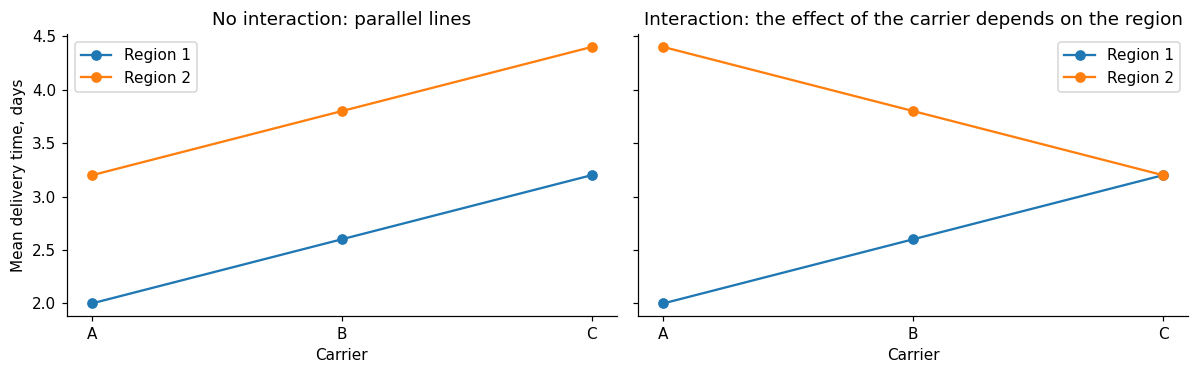

In [6]:
# @title
carriers = ["A", "B", "C"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
axes[0].plot(carriers, [2.0, 2.6, 3.2], marker="o", label="Region 1"); axes[0].plot(carriers, [3.2, 3.8, 4.4], marker="o", label="Region 2")
axes[0].set_title("No interaction: parallel lines"); axes[0].set_ylabel("Mean delivery time, days"); axes[0].set_xlabel("Carrier"); axes[0].legend()
axes[1].plot(carriers, [2.0, 2.6, 3.2], marker="o", label="Region 1"); axes[1].plot(carriers, [4.4, 3.8, 3.2], marker="o", label="Region 2")
axes[1].set_title("Interaction: the effect of the carrier depends on the region"); axes[1].set_xlabel("Carrier"); axes[1].legend()
plt.tight_layout(); plt.show()

### Example: delivery carriers

A retailer ships online orders through three carriers (A, B, and C) to urban and rural customers. Within each region, the retailer randomly assigned 15 orders to each carrier, 90 orders in total, and recorded the delivery time in days. The data are synthetic.

First, a one-way ANOVA comparing the three carriers:

In [25]:
# @title
deliveries = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/carrier_delivery_times.csv")
print(deliveries.groupby("carrier")["days"].mean().round(2))
f_stat, p_value = stats.f_oneway(*[g["days"] for _, g in deliveries.groupby("carrier")])
print(f"\nOne-way ANOVA by carrier: F = {f_stat:.2f}, p-value = {p_value:.3f}")

carrier
A   3.2200
B   3.2700
C   3.3000
Name: days, dtype: float64

One-way ANOVA by carrier: F = 0.04, p-value = 0.964


On average, the three carriers seem to be about equally fast, and the one-way ANOVA shows no evidence of a difference between them.

In [8]:
# @title
cell_means = deliveries.pivot_table(values="days", index="carrier", columns="region", aggfunc="mean")[["urban", "rural"]]
cell_means.round(2)

region,urban,rural
carrier,,
A,1.8700,4.5800
B,2.5900,3.9500
C,3.3500,3.2400


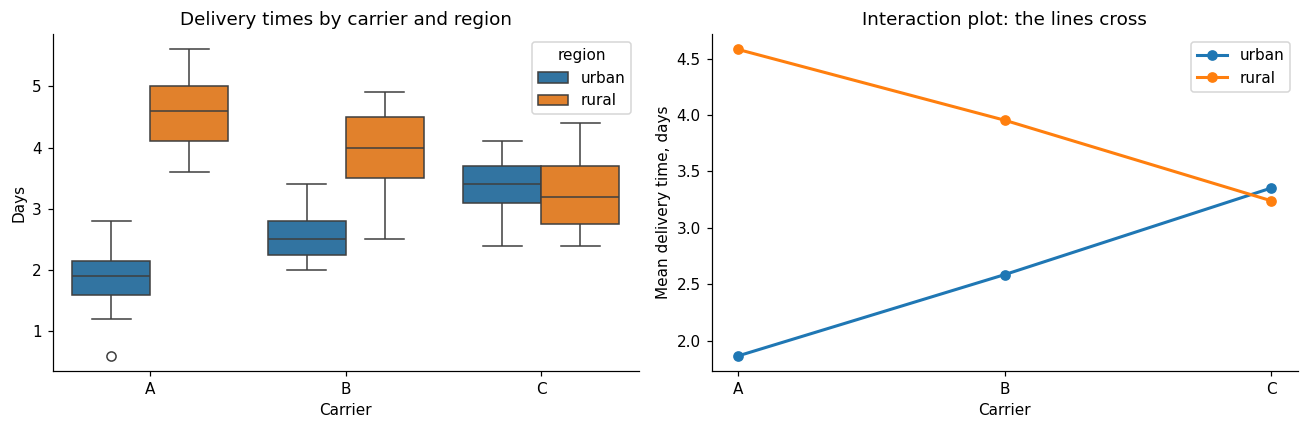

In [9]:
# @title
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=deliveries, x="carrier", y="days", hue="region", hue_order=["urban", "rural"], order=carriers, ax=axes[0])
axes[0].set_title("Delivery times by carrier and region"); axes[0].set_xlabel("Carrier"); axes[0].set_ylabel("Days")
for r in ["urban", "rural"]: axes[1].plot(carriers, cell_means[r], marker="o", lw=2, label=r)
axes[1].set_title("Interaction plot: the lines cross"); axes[1].set_xlabel("Carrier"); axes[1].set_ylabel("Mean delivery time, days"); axes[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# @title
model_a = ols("days ~ C(carrier) * C(region)", data=deliveries).fit()
sm.stats.anova_lm(model_a, typ=2)

,sum_sq,df,F,PR(>F)
C(carrier),0.0827,2.0000,0.1180,0.8888
C(region),39.3361,1.0000,112.2921,0.0000
C(carrier):C(region),29.9849,2.0000,42.7987,0.0000
Residual,29.4253,84.0000,NaN,NaN


How to read the table:

- `C(carrier)` and `C(region)` are the **main effects**: the effect of each factor, averaged over the other.
- `C(carrier):C(region)` is the **interaction**. Its p-value is tiny: the effect of the carrier differs by region.

When the interaction is significant, main effects are hard to interpret on their own. The main effect of the carrier is not significant here, but the carrier matters a lot: carrier A is the fastest in cities and the slowest in rural areas, carrier C delivers in about three days everywhere, and the differences cancel out on average. A plausible reason is that carrier A has a dense network of urban hubs, while carrier C relies on a regional network with good rural coverage.

Notice also the design. Carriers were randomly assigned to orders within each region, so the differences between carriers can be read as effects of the carrier. The region was not assigned: it describes where the customer lives. Rural orders take longer, but that comparison is observational, like the comparison of battery suppliers in notebook 10.2.

**Question to you:** a logistics manager sees only the one-way analysis by carrier and concludes that the choice of carrier does not matter. What would you tell her? Which carrier would you use for urban orders, and which for rural orders?

## Part B. When a comparison reverses: Simpson's paradox

A business school compares exam scores in morning and evening sections of the same course. Students chose their own sections. Many operations majors work full-time in supply chain jobs and take evening sections, while most human resources majors in this example are full-time students who take morning sections. Operations majors also come in with more quantitative coursework. The data are synthetic.

In [10]:
# @title
sections = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/section_scores_simpson.csv")
sections.groupby("section_time")["score"].agg(["count", "mean"])

,count,mean
section_time,,
evening,50,7.8400
morning,50,7.4100


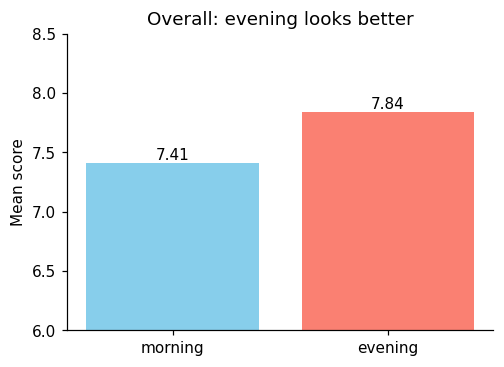

In [16]:
# @title
tp = {"morning": "skyblue", "evening": "salmon"}
overall = sections.groupby("section_time")["score"].mean()[["morning", "evening"]]
plt.figure(figsize=(5, 3.5))
plt.bar(overall.index, overall, color=[tp[s] for s in overall.index])
for i, v in enumerate(overall): plt.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.ylim(6, 8.5); plt.ylabel("Mean score"); plt.title("Overall: evening looks better"); plt.show()

In [17]:
# @title
evening = sections.loc[sections["section_time"] == "evening", "score"]
morning = sections.loc[sections["section_time"] == "morning", "score"]
t_stat, p_value = stats.ttest_ind(evening, morning)
print(f"Evening minus morning: {evening.mean() - morning.mean():.2f}, p-value = {p_value:.3f}")

Evening minus morning: 0.43, p-value = 0.162


The difference favors the evening, though it is not significant. Now split the comparison by major.

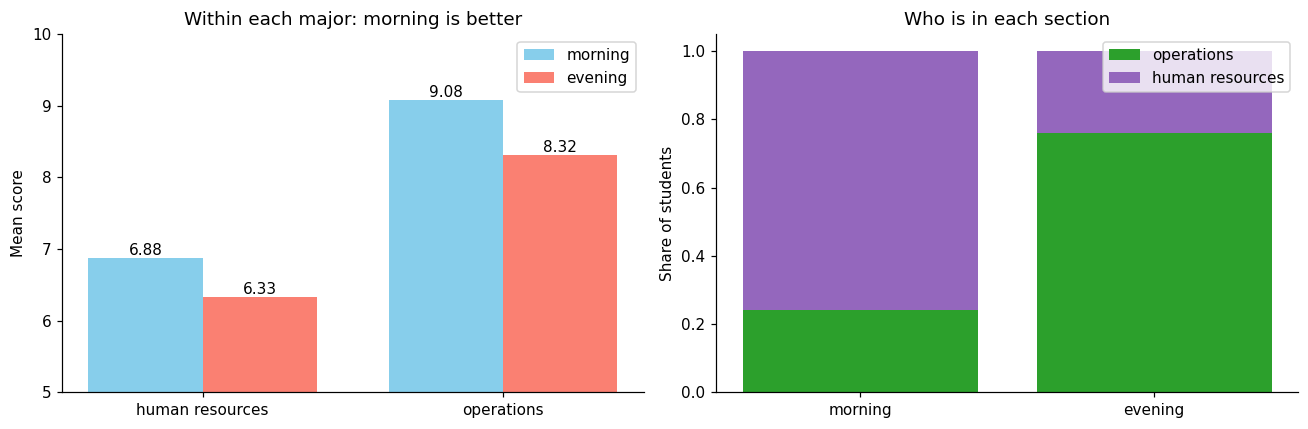

In [18]:
# @title
within = sections.pivot_table(values="score", index="major", columns="section_time", aggfunc="mean")[["morning", "evening"]]
counts = pd.crosstab(sections["major"], sections["section_time"])[["morning", "evening"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(2); w = 0.38
for j, s in enumerate(["morning", "evening"]):
    axes[0].bar(x + (j - 0.5) * w, within[s], w, color=tp[s], label=s)
    for i, v in enumerate(within[s]): axes[0].text(i + (j - 0.5) * w, v, f"{v:.2f}", ha="center", va="bottom")
axes[0].set_xticks(x); axes[0].set_xticklabels(within.index); axes[0].set_ylim(5, 10)
axes[0].set_title("Within each major: morning is better"); axes[0].set_ylabel("Mean score"); axes[0].legend()
share = counts / counts.sum()
axes[1].bar(["morning", "evening"], share.loc["operations"], color="tab:green", label="operations")
axes[1].bar(["morning", "evening"], share.loc["human resources"], bottom=share.loc["operations"], color="tab:purple", label="human resources")
axes[1].set_title("Who is in each section"); axes[1].set_ylabel("Share of students"); axes[1].legend()
plt.tight_layout(); plt.show()

Within each major, **morning** students score higher. The overall comparison points the other way because most evening students are operations majors, and operations majors score higher in both section times. The overall comparison mixes the effect of the section time with the effect of the major.

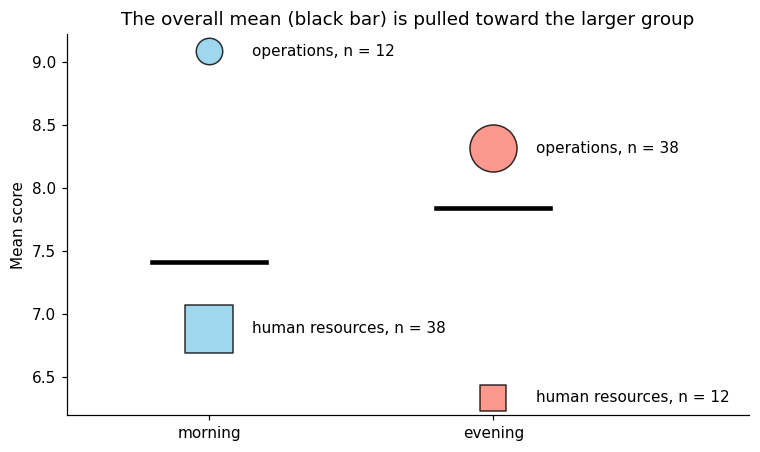

In [23]:
# @title
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, s in enumerate(["morning", "evening"]):
    for mj, mk in zip(["operations", "human resources"], ["o", "s"]):
        ax.scatter(j, within.loc[mj, s], s=counts.loc[mj, s] * 25, color=tp[s], edgecolor="black", marker=mk, alpha=0.8)
        ax.text(j + 0.15, within.loc[mj, s], f"{mj}, n = {counts.loc[mj, s]}", va="center")
    ax.plot([j - 0.2, j + 0.2], [overall[s]] * 2, color="black", lw=3)
ax.set_xticks([0, 1]); ax.set_xticklabels(["morning", "evening"]); ax.set_xlim(-0.5, 1.9)
ax.set_ylabel("Mean score"); ax.set_title("The overall mean (black bar) is pulled toward the larger group")
plt.show()

A two-way ANOVA compares the section times **within** each major.

In [24]:
# @title
model_b = ols("score ~ C(section_time) + C(major)", data=sections).fit()
sm.stats.anova_lm(model_b, typ=2)

,sum_sq,df,F,PR(>F)
C(section_time),7.8947,1.0000,5.1662,0.0252
C(major),79.8347,1.0000,52.2428,0.0000
Residual,148.2303,97.0000,NaN,NaN


Once major is taken into account, the section time is significant at α = 0.05, in the opposite direction to the overall comparison: morning sections do better.

This is **Simpson's paradox**: a comparison that holds within every subgroup reverses when the subgroups are combined. It happens when the groups we compare contain different mixes of a variable that also affects the response. Here the major is a confounder: it affects both the choice of section and the score. In Module 12 you will see the same reversal in a regression, when a coefficient changes sign after another variable is added.

**Question to you:** the dean wants to move more courses to the evening because "evening students score higher". What would you tell the dean? Would randomly assigning students to sections settle the question?